In [1]:
import sys
from pathlib import Path
import importlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


# --------------------------------------------------
# Paths
# --------------------------------------------------

ROOT = Path.cwd()

FITS_ROOT = ROOT / "fits_files"

# Full sample:
# fits_files/MUSE-30Dor-H-bin0_02
# fits_files/SAMFP-30Dor-Ha-bin0_02
FITS_DIR_FULL = FITS_ROOT

# Trimmed sample:
# fits_files/trim_files/MUSE-30Dor-H-bin0_02
# fits_files/trim_files/SAMFP-30Dor-Ha-bin0_02
FITS_DIR_TRIM = FITS_ROOT / "trim_files"

# Comparison outputs
FIGS_DIR = ROOT / "figures" / "full_vs_trim"
OUTPUT_DIR = ROOT / "results_tables" / "full_vs_trim"

FIGS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print(f"Full FITS: {FITS_DIR_FULL}")
print(f"Trim FITS: {FITS_DIR_TRIM}")
print(f"Figures:   {FIGS_DIR}")
print(f"Tables:    {OUTPUT_DIR}")


# --------------------------------------------------
# Local modules
# --------------------------------------------------

sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "py_modules"))

import results_comp
import fit_fraction_latex_tools as ffa

ffa = importlib.reload(ffa)

sns.set_context("talk")


Full FITS: C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\30dor\analysis_v1\fits_files
Trim FITS: C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\30dor\analysis_v1\fits_files\trim_files
Figures:   C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\30dor\analysis_v1\figures\full_vs_trim
Tables:    C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\30dor\analysis_v1\results_tables\full_vs_trim


# Configuration

This notebook processes the four samples simultaneously:

- **MUSE-full** from `fits_files/`
- **MUSE-trim** from `fits_files/trim_files/`
- **SAMFP-full** from `fits_files/`
- **SAMFP-trim** from `fits_files/trim_files/`

The FITS filenames remain identical between the full and trimmed directories.  
The `group` key distinguishes the four samples throughout the analysis.


The complete \(L_{\rm frac}\) grid is common to all samples.  
The adopted fractions are defined independently later through `FIT_LIMITS_BY_GROUP`.


In [2]:
ALL_FIT_LIMITS = (
    0.2,
    0.3,
    0.4,
    0.5,
    0.6,
    0.7,
    0.8,
    0.9,
    1.0
)

In [3]:
DATASET_CONFIGS_FULL = [
    {
        "group": "MUSE-full",
        "dataset_prefix": "MUSE-30Dor",
        "bin_levels": (0,),
        "line_order": ("H",),
        "filename_template":
            "{dataset_prefix}-{file_line}-bin{bin}_{fit_tag}",
    },

    {
        "group": "SAMFP-full",
        "dataset_prefix": "SAMFP-30Dor",
        "bin_levels": (0,),
        "line_order": ("H",),

        # Internal key H, but filename uses Ha
        "file_line_ids": {
            "H": "Ha",
        },

        "filename_template":
            "{dataset_prefix}-{file_line}-bin{bin}_{fit_tag}",
    },
]


DATASET_CONFIGS_TRIM = [
    {
        "group": "MUSE-trim",
        "dataset_prefix": "MUSE-30Dor",
        "bin_levels": (0,),
        "line_order": ("H",),
        "filename_template":
            "{dataset_prefix}-{file_line}-bin{bin}_{fit_tag}",
    },

    {
        "group": "SAMFP-trim",
        "dataset_prefix": "SAMFP-30Dor",
        "bin_levels": (0,),
        "line_order": ("H",),

        # Internal key H, but filename uses Ha
        "file_line_ids": {
            "H": "Ha",
        },

        "filename_template":
            "{dataset_prefix}-{file_line}-bin{bin}_{fit_tag}",
    },
]


# Preferred ordering in tables and final comparison figures
GROUP_ORDER = (
    "MUSE-full",
    "MUSE-trim",
    "SAMFP-full",
    "SAMFP-trim",
)

# Pair full and trim versions for direct Lfrac comparisons
COMPARISON_GROUPS = {
    "MUSE": (
        "MUSE-full",
        "MUSE-trim",
    ),
    "SAMFP": (
        "SAMFP-full",
        "SAMFP-trim",
    ),
}


Preview the expected files

In [4]:
samples_full = ffa.build_fraction_sample_grid(
    DATASET_CONFIGS_FULL,
    ALL_FIT_LIMITS,
)

samples_trim = ffa.build_fraction_sample_grid(
    DATASET_CONFIGS_TRIM,
    ALL_FIT_LIMITS,
)

samples = (
    samples_full
    + samples_trim
)

sample_table = pd.DataFrame(samples)[
    [
        "group",
        "bin",
        "line",
        "fit_limit",
        "file_name",
    ]
]

display(sample_table)


,group,bin,line,fit_limit,file_name
0,MUSE-full,0,H,0.2,MUSE-30Dor-H-bin0_02
1,MUSE-full,0,H,0.3,MUSE-30Dor-H-bin0_03
2,MUSE-full,0,H,0.4,MUSE-30Dor-H-bin0_04
3,MUSE-full,0,H,0.5,MUSE-30Dor-H-bin0_05
4,MUSE-full,0,H,0.6,MUSE-30Dor-H-bin0_06
5,MUSE-full,0,H,0.7,MUSE-30Dor-H-bin0_07
6,MUSE-full,0,H,0.8,MUSE-30Dor-H-bin0_08
7,MUSE-full,0,H,0.9,MUSE-30Dor-H-bin0_09
8,MUSE-full,0,H,1.0,MUSE-30Dor-H-bin0_10
9,SAMFP-full,0,H,0.2,SAMFP-30Dor-Ha-bin0_02


Load the complete \(L_{\rm frac}\)

In [5]:
full_fraction_results, failures_full = (
    ffa.load_multi_line_bin_fraction_results(
        results_comp,
        FITS_DIR_FULL,
        dataset_configs=DATASET_CONFIGS_FULL,
        fit_limits=ALL_FIT_LIMITS,
        read_header=True,
        on_error="warn",
        return_failures=True,
    )
)

trim_fraction_results, failures_trim = (
    ffa.load_multi_line_bin_fraction_results(
        results_comp,
        FITS_DIR_TRIM,
        dataset_configs=DATASET_CONFIGS_TRIM,
        fit_limits=ALL_FIT_LIMITS,
        read_header=True,
        on_error="warn",
        return_failures=True,
    )
)

# Merge the four samples into one analysis collection
all_fraction_results = (
    full_fraction_results
    + trim_fraction_results
)

failures = (
    [
        {
            **failure,
            "sample": "full",
        }
        for failure in failures_full
    ]
    +
    [
        {
            **failure,
            "sample": "trim",
        }
        for failure in failures_trim
    ]
)

print(f"Loaded full: {len(full_fraction_results)}")
print(f"Loaded trim: {len(trim_fraction_results)}")
print(f"Loaded total: {len(all_fraction_results)}")
print(f"Unavailable: {len(failures)}")

if failures:
    display(
        pd.DataFrame(failures)[
            [
                "sample",
                "file_name",
                "error",
            ]
        ]
    )


Loaded full: 18
Loaded trim: 18
Loaded total: 36
Unavailable: 0


Convert the complete sample to a tidy table

In [6]:
fraction_table = ffa.results_to_dataframe(
    all_fraction_results
)

display(fraction_table)

,group,bin,line,fit_limit,fit_limits_used,selection_mode,parameter,value,err_lower,err_upper,lower_limit,upper_limit,n_samples
0,MUSE-full,0,H,0.2,None,None,sig2,210.543238,17.264807,55.109408,193.278431,265.652646,None
1,MUSE-full,0,H,0.2,None,None,r0,2.276951,0.252627,0.948468,2.024325,3.225420,None
2,MUSE-full,0,H,0.2,None,None,m,1.068738,0.144998,0.068789,0.923740,1.137527,None
3,MUSE-full,0,H,0.2,None,None,noise,5.104529,0.589824,0.592156,4.514705,5.696685,None
4,MUSE-full,0,H,0.2,None,None,s0,0.079662,0.021701,0.043032,0.057960,0.122693,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,SAMFP-trim,0,H,1.0,None,None,sig2,630.357706,226.034290,224.887743,404.323416,855.245448,None
176,SAMFP-trim,0,H,1.0,None,None,r0,25.279368,15.088768,20.557432,10.190600,45.836800,None
177,SAMFP-trim,0,H,1.0,None,None,m,0.659333,0.058224,0.086868,0.601109,0.746201,None
178,SAMFP-trim,0,H,1.0,None,None,noise,4.766073,0.641635,0.650147,4.124438,5.416220,None


Section 3 — inspect the complete \(L_{\rm frac}\) sample

In [7]:
PARAMETERS = ("sig2", "r0", "m", "noise", "s0")

PARAM_LABELS = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [pc]",
}

PARAM_TITLES = {
    "sig2": r"$\sigma^2$",
    "r0": r"$r_0$",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$",
    "s0": r"$s_0$",
}

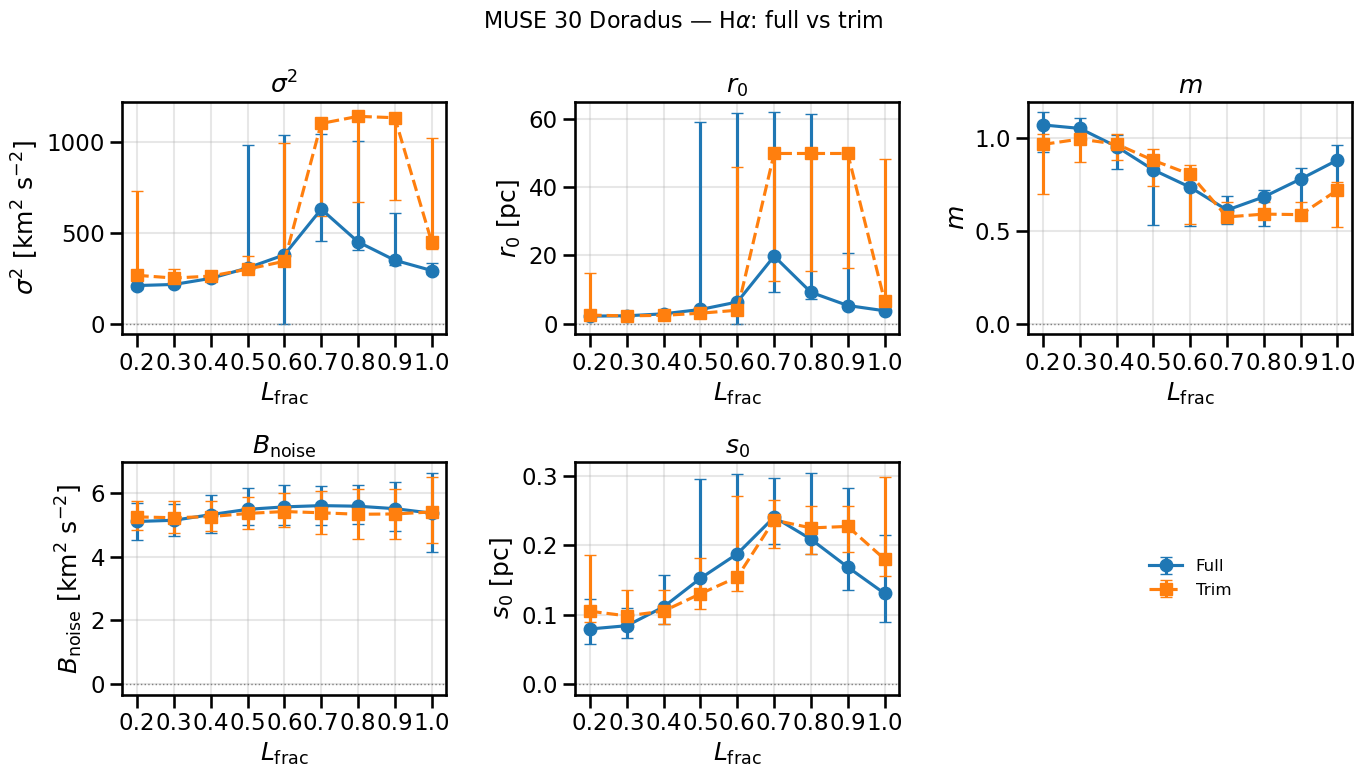

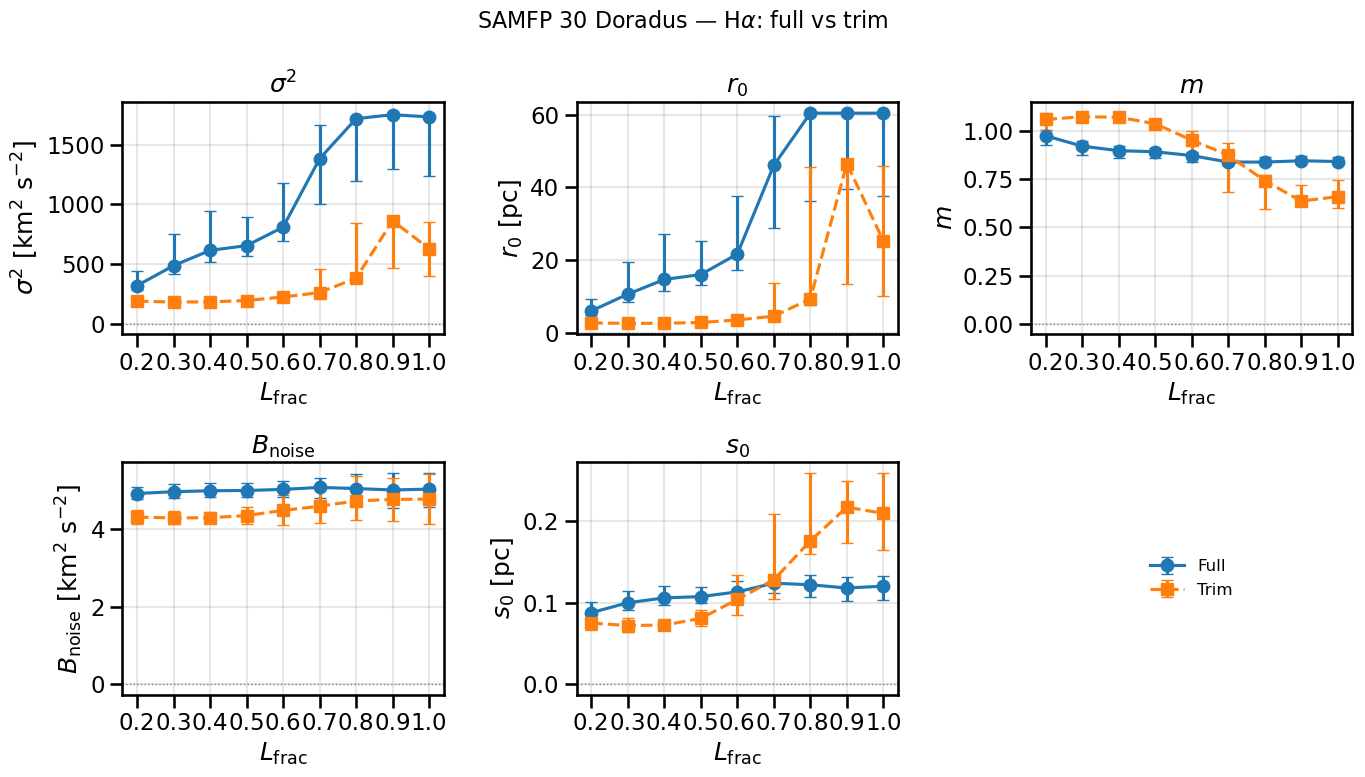

In [8]:
for instrument, groups in COMPARISON_GROUPS.items():

    fig, axes = plt.subplots(
        2, 3,
        figsize=(14, 8),
    )

    axes = axes.ravel()

    for ax, param in zip(axes, PARAMETERS):

        for group in groups:

            df_param = (
                fraction_table[
                    (fraction_table["parameter"] == param)
                    &
                    (fraction_table["group"] == group)
                ]
                .sort_values("fit_limit")
            )

            if df_param.empty:
                continue

            x = df_param["fit_limit"].to_numpy()
            y = df_param["value"].to_numpy(dtype=float)

            err_lower = df_param["err_lower"].to_numpy(dtype=float)
            err_upper = df_param["err_upper"].to_numpy(dtype=float)

            # Negative lower uncertainty:
            # plot the interval down to the physical boundary at zero.
            bad_lower = err_lower < 0

            err_lower_plot = np.where(
                bad_lower,
                y,
                np.abs(err_lower),
            )

            err_upper_plot = np.abs(
                err_upper
            )

            yerr = np.vstack([
                err_lower_plot,
                err_upper_plot,
            ])

            sample_type = (
                "Full"
                if group.endswith("-full")
                else "Trim"
            )

            marker = (
                "o"
                if sample_type == "Full"
                else "s"
            )

            linestyle = (
                "-"
                if sample_type == "Full"
                else "--"
            )

            ax.errorbar(
                x,
                y,
                yerr=yerr,
                marker=marker,
                linestyle=linestyle,
                capsize=4,
                label=sample_type,
            )

        ax.axhline(
            0.0,
            color="0.5",
            linestyle=":",
            linewidth=1.0,
        )

        ax.set_title(
            PARAM_TITLES[param]
        )

        ax.set_xlabel(
            r"$L_{\rm frac}$"
        )

        ax.set_ylabel(
            PARAM_LABELS[param]
        )

        ax.set_xticks(
            ALL_FIT_LIMITS
        )

        ax.grid(
            alpha=0.3
        )

    axes[-1].axis("off")

    handles, labels = (
        axes[0].get_legend_handles_labels()
    )

    axes[-1].legend(
        handles,
        labels,
        loc="center",
        frameon=False,
        fontsize=12,
    )

    fig.suptitle(
        rf"{instrument} 30 Doradus — H$\alpha$: full vs trim",
        fontsize=16,
    )

    fig.tight_layout()

    fig.savefig(
        FIGS_DIR
        / f"{instrument}_30Dor_H_full_vs_trim_Lfrac.jpg",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()


Visually indicate the fractions selected for the final result

In [9]:
# The adopted Lfrac values are defined independently
# for each of the four samples in the next cell.


In [10]:
FIT_LIMITS_BY_GROUP = {
    # Full samples
    "MUSE-full": (
        0.2,
        0.3,
        0.4,
    ),

    "SAMFP-full": (
        0.2,
    #    0.3,
    #    0.4,
    ),

    # Trim samples
    #
    # These are initial choices copied from the corresponding
    # full samples. Revise them after inspecting the trim
    # Lfrac behavior above.
    "MUSE-trim": (
        0.3,
        0.4,
        0.5,
    ),

    "SAMFP-trim": (
        0.3,
        0.4,
        0.5,
    ),
}


The selected fractions are now handled independently through `FIT_LIMITS_BY_GROUP`.  
The next diagnostic plots show the selected points and adopted average for each of the four samples.


Downstream selection and averaging

In [11]:
selected_results_pc = (
    ffa.select_or_average_fit_results(
        all_fraction_results,
        fit_limits_by_group=FIT_LIMITS_BY_GROUP,
        group_keys=("group", "bin", "line"),
    )
)

selected_table_pc = ffa.results_to_dataframe(
    selected_results_pc
)

display(selected_table_pc)

,group,bin,line,fit_limit,fit_limits_used,selection_mode,parameter,value,err_lower,err_upper,lower_limit,upper_limit,n_samples
0,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,sig2,225.710123,32.431691,65.061026,193.278431,290.771149,3
1,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,r0,2.529723,0.505398,1.287584,2.024325,3.817306,3
2,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,m,1.023771,0.189899,0.113757,0.833872,1.137527,3
3,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,noise,5.188290,0.673585,0.731041,4.514705,5.919331,3
4,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,s0,0.091828,0.033868,0.065546,0.057960,0.157374,3
5,SAMFP-full,0,H,0.2,"(0.2,)",single,sig2,320.553726,40.084629,123.134379,280.469097,443.688104,1
6,SAMFP-full,0,H,0.2,"(0.2,)",single,r0,5.973963,1.011408,3.401995,4.962555,9.375957,1
7,SAMFP-full,0,H,0.2,"(0.2,)",single,m,0.975209,0.049052,0.028115,0.926156,1.003324,1
8,SAMFP-full,0,H,0.2,"(0.2,)",single,noise,4.909866,0.140099,0.155467,4.769766,5.065333,1
9,SAMFP-full,0,H,0.2,"(0.2,)",single,s0,0.087726,0.007789,0.012749,0.079937,0.100475,1


In [12]:
PARAMETERS = ("sig2", "r0", "m", "noise", "s0")

PARAM_LABELS = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [pc]",
}

PARAM_TITLES = {
    "sig2": r"$\sigma^2$",
    "r0": r"$r_0$",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$",
    "s0": r"$s_0$",
}

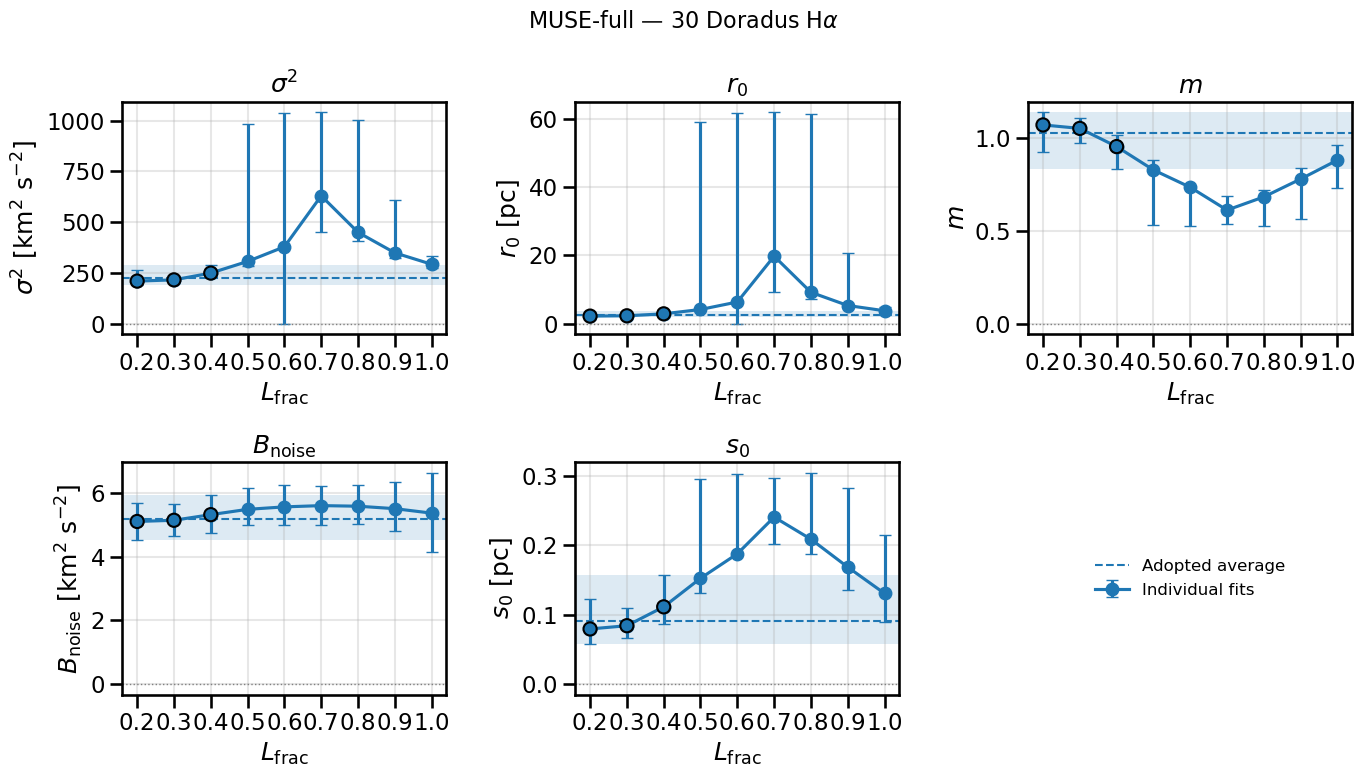

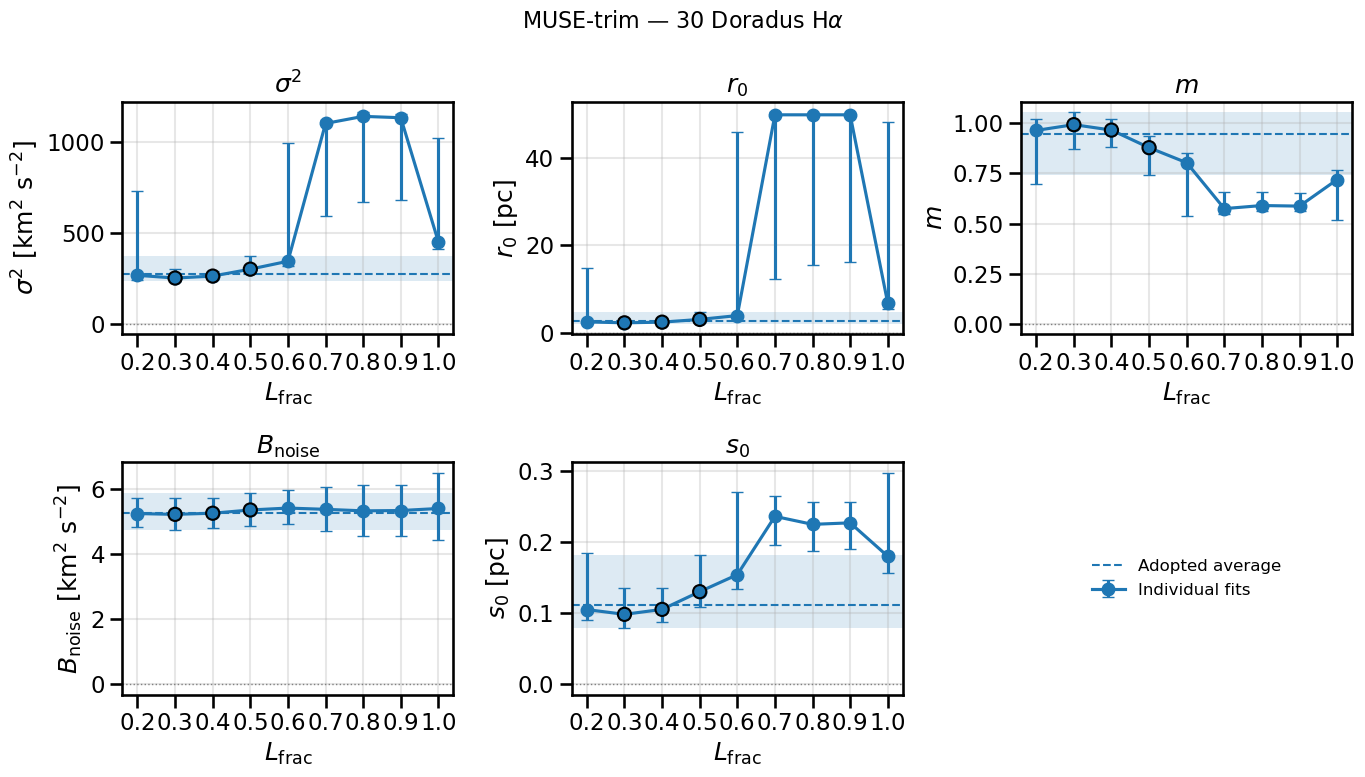

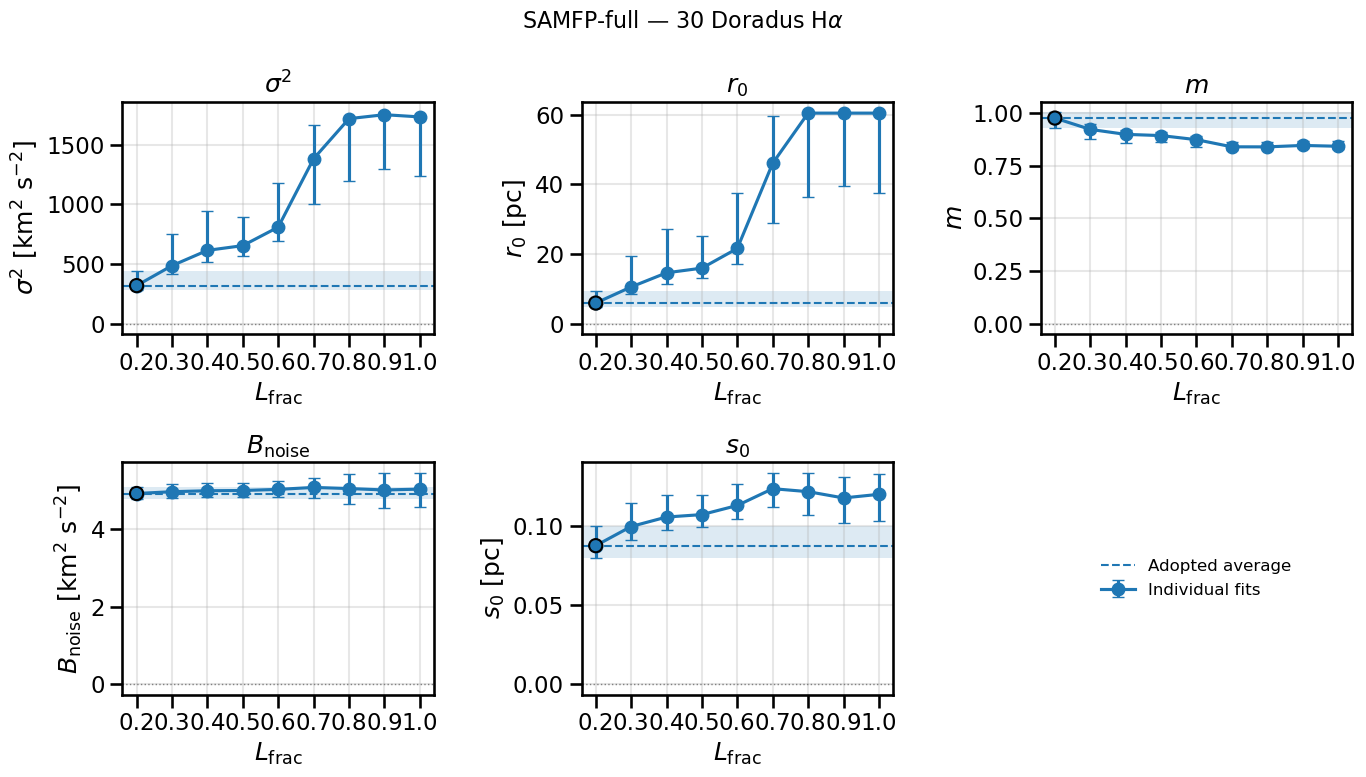

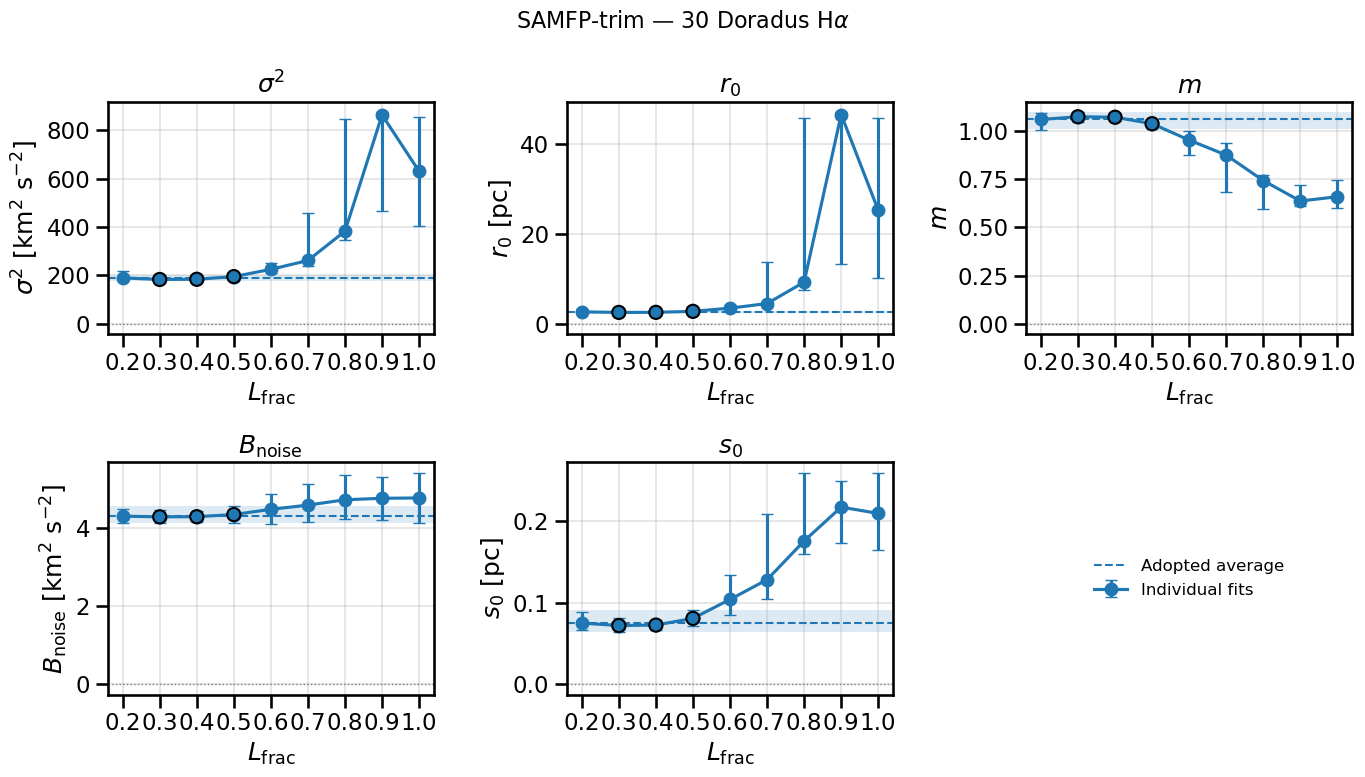

In [13]:
GROUPS_TO_PLOT = GROUP_ORDER

for group in GROUPS_TO_PLOT:

    fig, axes = plt.subplots(
        2, 3,
        figsize=(14, 8),
    )

    axes = axes.ravel()

    # Selected Lfrac values for this instrument
    selected_fit_limits = FIT_LIMITS_BY_GROUP[group]

    # Fit limits available for this instrument
    group_fit_limits = tuple(
        sorted(
            fraction_table.loc[
                fraction_table["group"] == group,
                "fit_limit",
            ].unique()
        )
    )

    for ax, param in zip(axes, PARAMETERS):

        # --------------------------------------------------
        # Complete Lfrac sample for this instrument
        # --------------------------------------------------
        df_raw = (
            fraction_table[
                (fraction_table["parameter"] == param)
                &
                (fraction_table["group"] == group)
            ]
            .sort_values("fit_limit")
        )

        x = df_raw["fit_limit"].to_numpy()
        y = df_raw["value"].to_numpy(dtype=float)

        err_lower = df_raw["err_lower"].to_numpy(dtype=float)
        err_upper = df_raw["err_upper"].to_numpy(dtype=float)

        # --------------------------------------------------
        # Error-bar treatment
        #
        # Negative lower uncertainties are interpreted as
        # extending to the physical boundary at zero.
        # --------------------------------------------------
        bad_lower = err_lower < 0

        err_lower_plot = np.where(
            bad_lower,
            y,
            np.abs(err_lower),
        )

        err_upper_plot = np.abs(
            err_upper
        )

        yerr = np.vstack([
            err_lower_plot,
            err_upper_plot,
        ])

        ax.errorbar(
            x,
            y,
            yerr=yerr,
            marker="o",
            linestyle="-",
            capsize=4,
            label="Individual fits",
        )

        # --------------------------------------------------
        # Selected / averaged result for this instrument
        # --------------------------------------------------
        df_avg = selected_table_pc[
            (selected_table_pc["parameter"] == param)
            &
            (selected_table_pc["group"] == group)
        ]

        if len(df_avg) == 1:

            avg = float(
                df_avg["value"].iloc[0]
            )

            avg_lower = float(
                df_avg["err_lower"].iloc[0]
            )

            avg_upper = float(
                df_avg["err_upper"].iloc[0]
            )

            # Same convention for a negative
            # lower uncertainty
            if avg_lower < 0:
                lower_limit = 0.0
            else:
                lower_limit = avg - abs(avg_lower)

            upper_limit = (
                avg + abs(avg_upper)
            )

            # Mean adopted value
            ax.axhline(
                avg,
                linestyle="--",
                linewidth=1.5,
                label="Adopted average",
            )

            # Full uncertainty envelope
            ax.axhspan(
                lower_limit,
                upper_limit,
                alpha=0.15,
            )

        # --------------------------------------------------
        # Mark selected Lfrac values
        # --------------------------------------------------
        selected_mask = (
            df_raw["fit_limit"]
            .isin(selected_fit_limits)
        )

        ax.scatter(
            df_raw.loc[
                selected_mask,
                "fit_limit",
            ],
            df_raw.loc[
                selected_mask,
                "value",
            ],
            s=90,
            facecolors="none",
            edgecolors="black",
            linewidths=1.5,
            zorder=5,
        )

        # --------------------------------------------------
        # Reference line
        # --------------------------------------------------
        ax.axhline(
            0.0,
            color="0.5",
            linestyle=":",
            linewidth=1.0,
        )

        # --------------------------------------------------
        # Axes
        # --------------------------------------------------
        ax.set_title(
            PARAM_TITLES[param]
        )

        ax.set_xlabel(
            r"$L_{\rm frac}$"
        )

        ax.set_ylabel(
            PARAM_LABELS[param]
        )

        ax.set_xticks(
            group_fit_limits
        )

        ax.grid(
            alpha=0.3
        )

    # --------------------------------------------------
    # Legend in empty panel
    # --------------------------------------------------
    axes[-1].axis("off")

    handles, labels = (
        axes[0].get_legend_handles_labels()
    )

    axes[-1].legend(
        handles,
        labels,
        loc="center",
        frameon=False,
        fontsize=12,
    )

    # --------------------------------------------------
    # Figure title
    # --------------------------------------------------
    fig.suptitle(
        rf"{group} — 30 Doradus H$\alpha$",
        fontsize=16,
    )

    fig.tight_layout()

    # --------------------------------------------------
    # Save
    # --------------------------------------------------
    fig.savefig(
        FIGS_DIR
        / f"{group}_30Dor_H_Lfrac_diagnostics.jpg",
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

In [14]:
adopted_table = (
    selected_table_pc[
        [
            "group",
            "line",
            "fit_limits_used",
            "parameter",
            "value",
            "err_lower",
            "err_upper",
        ]
    ]
    .copy()
)

display(adopted_table)


,group,line,fit_limits_used,parameter,value,err_lower,err_upper
0,MUSE-full,H,"(0.2, 0.3, 0.4)",sig2,225.710123,32.431691,65.061026
1,MUSE-full,H,"(0.2, 0.3, 0.4)",r0,2.529723,0.505398,1.287584
2,MUSE-full,H,"(0.2, 0.3, 0.4)",m,1.023771,0.189899,0.113757
3,MUSE-full,H,"(0.2, 0.3, 0.4)",noise,5.188290,0.673585,0.731041
4,MUSE-full,H,"(0.2, 0.3, 0.4)",s0,0.091828,0.033868,0.065546
5,SAMFP-full,H,"(0.2,)",sig2,320.553726,40.084629,123.134379
6,SAMFP-full,H,"(0.2,)",r0,5.973963,1.011408,3.401995
7,SAMFP-full,H,"(0.2,)",m,0.975209,0.049052,0.028115
8,SAMFP-full,H,"(0.2,)",noise,4.909866,0.140099,0.155467
9,SAMFP-full,H,"(0.2,)",s0,0.087726,0.007789,0.012749


In [15]:
selected_results = ffa.convert_s0_pc_to_arcsec(
    selected_results_pc,
    fwhm_factor=2.355,
    copy=True,
)

selected_table = ffa.results_to_dataframe(
    selected_results
)

display(selected_table)

,group,bin,line,fit_limit,fit_limits_used,selection_mode,parameter,value,err_lower,err_upper,lower_limit,upper_limit,n_samples
0,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,sig2,225.710123,32.431691,65.061026,193.278431,290.771149,3
1,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,r0,2.529723,0.505398,1.287584,2.024325,3.817306,3
2,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,m,1.023771,0.189899,0.113757,0.833872,1.137527,3
3,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,noise,5.188290,0.673585,0.731041,4.514705,5.919331,3
4,MUSE-full,0,H,NaN,"(0.2, 0.3, 0.4)",average,s0,0.892114,0.329026,0.636786,0.563088,1.528900,3
5,SAMFP-full,0,H,0.2,"(0.2,)",single,sig2,320.553726,40.084629,123.134379,280.469097,443.688104,1
6,SAMFP-full,0,H,0.2,"(0.2,)",single,r0,5.973963,1.011408,3.401995,4.962555,9.375957,1
7,SAMFP-full,0,H,0.2,"(0.2,)",single,m,0.975209,0.049052,0.028115,0.926156,1.003324,1
8,SAMFP-full,0,H,0.2,"(0.2,)",single,noise,4.909866,0.140099,0.155467,4.769766,5.065333,1
9,SAMFP-full,0,H,0.2,"(0.2,)",single,s0,0.852262,0.075672,0.123861,0.776590,0.976123,1


In [16]:
PARAMETERS = ("sig2", "r0", "m", "noise", "s0")

PARAM_LABELS_FINAL = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [arcsec]",
}

PARAM_TITLES = {
    "sig2": r"$\sigma^2$",
    "r0": r"$r_0$",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$",
    "s0": r"$s_0$",
}

# Combined adopted-result comparison

The next cell compares the adopted parameters for all four samples:
MUSE-full, MUSE-trim, SAMFP-full, and SAMFP-trim.


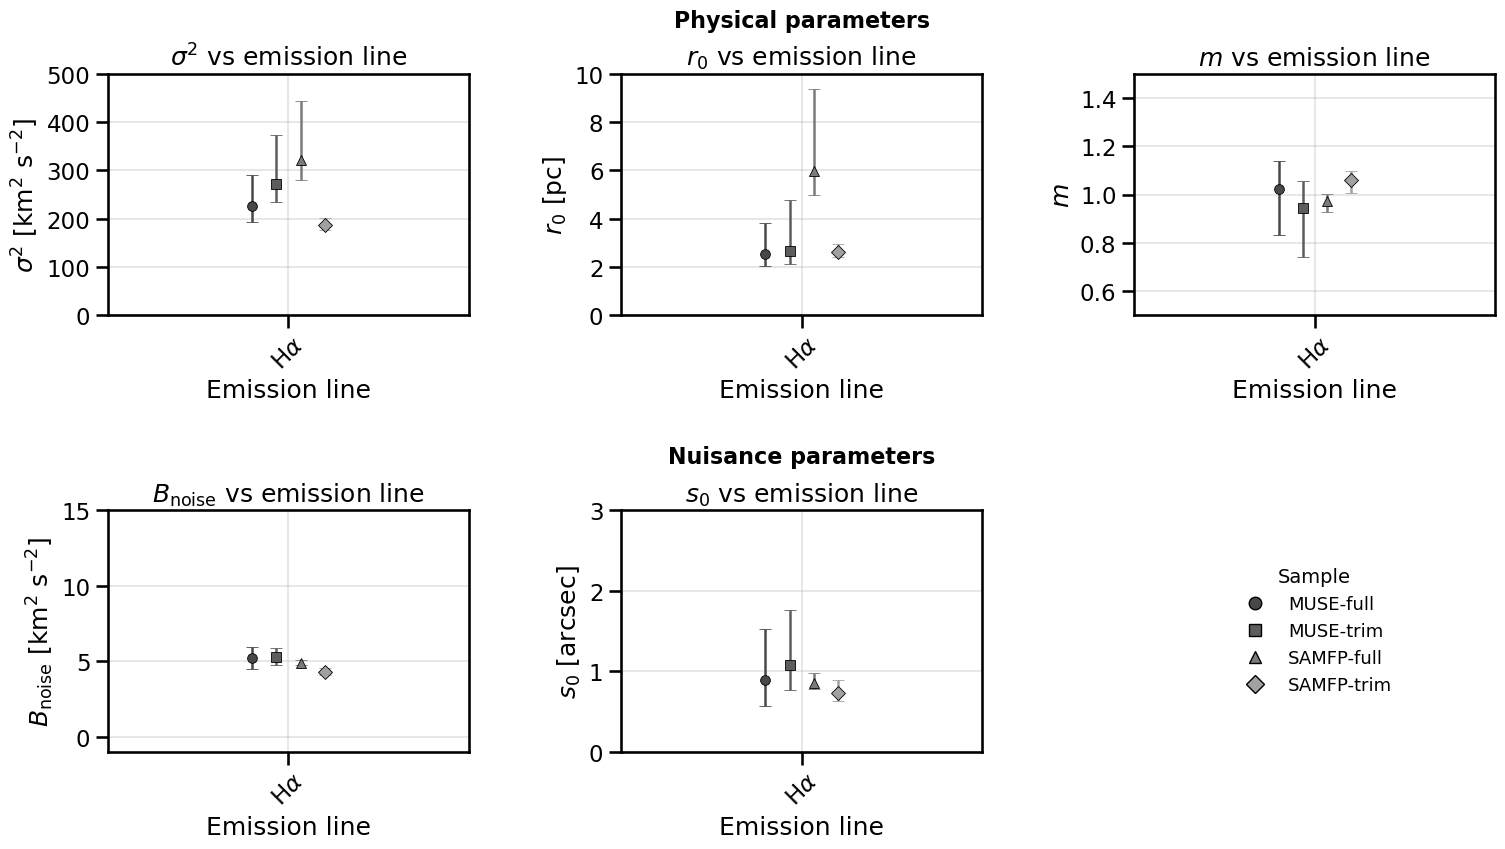

In [24]:
sample_selected = selected_results

# --------------------------------------------------
# Labels
# --------------------------------------------------

LINE_LABELS = {
    "H": r"H$\alpha$",
}

PARAM_LABELS_ARCSEC = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [arcsec]",
}


# --------------------------------------------------
# Plot adopted results for all four samples
# --------------------------------------------------

fig_samples, axes_samples = ffa.plot_param_grid_lines_as_x(
    sample_selected,

    line_order=("H",),

    group_order=GROUP_ORDER,
    group_key="group",

    line_labels=LINE_LABELS,
    param_labels=PARAM_LABELS_ARCSEC,

    param_ylims={
        "sig2": (0, 500),
        "r0": (0, 10),
        "m": (0.5, 1.5),
        "noise": (-1, 15),
        "s0": (0, 3),
    },

    row_titles=(
        "Physical parameters",
        "Nuisance parameters",
    ),

    row_title_fontsize=16,
    figsize=(15, 9),

    jitter=0.10,

    save=True,
    savepath=(
        FIGS_DIR
        / "fit_fraction_average_full_vs_trim.pdf"
    ),
)

# --------------------------------------------------
# Panel formatting
# --------------------------------------------------

for ax in axes_samples[:5]:
    ax.set_box_aspect(None)
    ax.set_aspect("auto")


fig_samples.subplots_adjust(
    left=0.065,
    right=0.99,
    wspace=0.42,
)

plt.show()


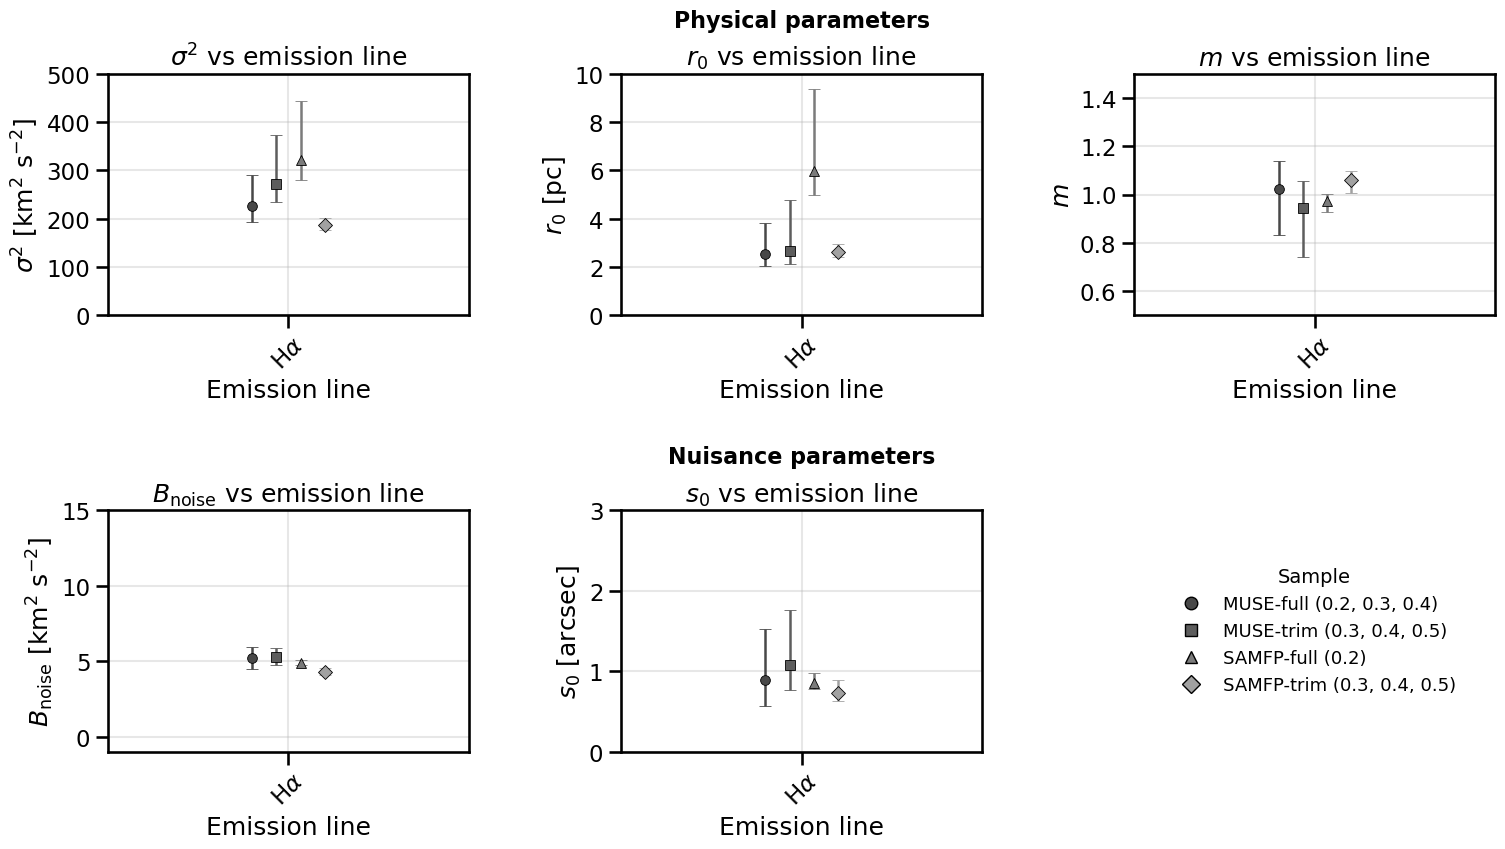

In [25]:
import copy

# --------------------------------------------------
# Copy selected results for plotting only
# --------------------------------------------------

sample_selected = copy.deepcopy(
    selected_results
)


# --------------------------------------------------
# Labels
# --------------------------------------------------

LINE_LABELS = {
    "H": r"H$\alpha$",
}

PARAM_LABELS_ARCSEC = {
    "sig2": r"$\sigma^2$ [km$^2$ s$^{-2}$]",
    "r0": r"$r_0$ [pc]",
    "m": r"$m$",
    "noise": r"$B_\mathrm{noise}$ [km$^2$ s$^{-2}$]",
    "s0": r"$s_0$ [arcsec]",
}


# --------------------------------------------------
# Group labels including adopted Lfrac values
# --------------------------------------------------

GROUP_LABELS = {}

for group in GROUP_ORDER:

    fit_limits = FIT_LIMITS_BY_GROUP[group]

    limits_text = ", ".join(
        f"{value:.1f}"
        for value in fit_limits
    )

    GROUP_LABELS[group] = (
        f"{group} ({limits_text})"
    )


# Replace group names only in plotting copy
for entry in sample_selected:

    original_group = entry["group"]

    entry["group"] = GROUP_LABELS[
        original_group
    ]


# Group order using display labels
GROUP_ORDER_PLOT = tuple(
    GROUP_LABELS[group]
    for group in GROUP_ORDER
)


# --------------------------------------------------
# Plot adopted results for all four samples
# --------------------------------------------------

fig_samples, axes_samples = ffa.plot_param_grid_lines_as_x(
    sample_selected,

    line_order=("H",),

    group_order=GROUP_ORDER_PLOT,
    group_key="group",

    line_labels=LINE_LABELS,
    param_labels=PARAM_LABELS_ARCSEC,

    param_ylims={
        "sig2": (0, 500),
        "r0": (0, 10),
        "m": (0.5, 1.5),
        "noise": (-1, 15),
        "s0": (0, 3),
    },

    row_titles=(
        "Physical parameters",
        "Nuisance parameters",
    ),

    row_title_fontsize=16,
    figsize=(15, 9),

    jitter=0.10,

    save=True,
    savepath=(
        FIGS_DIR
        / "fit_fraction_average_full_vs_trim.pdf"
    ),
)


# --------------------------------------------------
# Panel formatting
# --------------------------------------------------

for ax in axes_samples[:5]:
    ax.set_box_aspect(None)
    ax.set_aspect("auto")


fig_samples.subplots_adjust(
    left=0.065,
    right=0.99,
    wspace=0.42,
)

plt.show()

In [18]:
adopted_summary = (
    selected_table[
        [
            "group",
            "line",
            "fit_limits_used",
            "parameter",
            "value",
            "err_lower",
            "err_upper",
        ]
    ]
    .copy()
)

display(adopted_summary)

,group,line,fit_limits_used,parameter,value,err_lower,err_upper
0,MUSE-full,H,"(0.2, 0.3, 0.4)",sig2,225.710123,32.431691,65.061026
1,MUSE-full,H,"(0.2, 0.3, 0.4)",r0,2.529723,0.505398,1.287584
2,MUSE-full,H,"(0.2, 0.3, 0.4)",m,1.023771,0.189899,0.113757
3,MUSE-full,H,"(0.2, 0.3, 0.4)",noise,5.188290,0.673585,0.731041
4,MUSE-full,H,"(0.2, 0.3, 0.4)",s0,0.892114,0.329026,0.636786
5,SAMFP-full,H,"(0.2,)",sig2,320.553726,40.084629,123.134379
6,SAMFP-full,H,"(0.2,)",r0,5.973963,1.011408,3.401995
7,SAMFP-full,H,"(0.2,)",m,0.975209,0.049052,0.028115
8,SAMFP-full,H,"(0.2,)",noise,4.909866,0.140099,0.155467
9,SAMFP-full,H,"(0.2,)",s0,0.852262,0.075672,0.123861


Build the final adopted-parameter table

In [19]:
FINAL_PARAMETERS = (
    "sig2",
    "r0",
    "m",
    "noise",
    "s0",
)

available_groups = set(
    selected_table["group"]
)

FINAL_GROUP_ORDER = tuple(
    group
    for group in GROUP_ORDER
    if group in available_groups
)

final_rows = []

for group in FINAL_GROUP_ORDER:

    df_group = selected_table[
        selected_table["group"] == group
    ]

    if df_group.empty:
        continue

    row = {
        "group": group,
        "line": df_group["line"].iloc[0],
        "fit_limits_used":
            df_group["fit_limits_used"].iloc[0],
    }

    for param in FINAL_PARAMETERS:

        df_param = df_group[
            df_group["parameter"] == param
        ]

        if df_param.empty:
            continue

        values = df_param.iloc[0]

        row[param] = values["value"]
        row[f"{param}_err_lower"] = (
            values["err_lower"]
        )
        row[f"{param}_err_upper"] = (
            values["err_upper"]
        )

    final_rows.append(row)

final_table = pd.DataFrame(
    final_rows
)

display(final_table)


,group,line,fit_limits_used,sig2,sig2_err_lower,sig2_err_upper,r0,r0_err_lower,r0_err_upper,m,m_err_lower,m_err_upper,noise,noise_err_lower,noise_err_upper,s0,s0_err_lower,s0_err_upper
0,MUSE-full,H,"(0.2, 0.3, 0.4)",225.710123,32.431691,65.061026,2.529723,0.505398,1.287584,1.023771,0.189899,0.113757,5.188290,0.673585,0.731041,0.892114,0.329026,0.636786
1,MUSE-trim,H,"(0.3, 0.4, 0.5)",271.652340,38.033540,102.604528,2.657807,0.554782,2.104948,0.945571,0.204773,0.109666,5.279045,0.530282,0.604269,1.082536,0.312120,0.683569
2,SAMFP-full,H,"(0.2,)",320.553726,40.084629,123.134379,5.973963,1.011408,3.401995,0.975209,0.049052,0.028115,4.909866,0.140099,0.155467,0.852262,0.075672,0.123861
3,SAMFP-trim,H,"(0.3, 0.4, 0.5)",187.761235,10.441282,14.533879,2.639323,0.209298,0.313453,1.060890,0.053240,0.036786,4.303543,0.188070,0.249528,0.729246,0.101443,0.157227


In [20]:
LATEX_LINE = "H"
LATEX_BIN = 0

latex_rows = []

for group in FINAL_GROUP_ORDER:

    result_pc = ffa.get_fit_result(
        selected_results_pc,
        group=group,
        bin_level=LATEX_BIN,
        line=LATEX_LINE,
    )

    row = ffa.format_fit_summary_row(
        result_pc,
        fwhm=2.355,
        include_identifiers=True,
        line_labels=LINE_LABELS,
        row_terminator=True,
    )

    latex_rows.append(row)

print("\n".join(latex_rows))

MUSE-full & 0 & H$\alpha$ & 0.2,0.3,0.4 & 225.71\PM{65.06}{32.43} & 2.530\PM{1.288}{0.505} & 1.02\PM{0.11}{0.19} & 5.188\PM{0.731}{0.674} & <1.53 & 9.33 & <0.0622 & 0.019 \\
MUSE-trim & 0 & H$\alpha$ & 0.3,0.4,0.5 & 271.65\PM{102.60}{38.03} & 2.658\PM{2.105}{0.555} & 0.95\PM{0.11}{0.20} & 5.279\PM{0.604}{0.530} & <1.77 & 10.14 & <0.0684 & 0.018 \\
SAMFP-full & 0 & H$\alpha$ & 0.2 & 320.55\PM{123.13}{40.08} & 5.974\PM{3.402}{1.011} & 0.98\PM{0.03}{0.05} & 4.910\PM{0.155}{0.140} & <0.98 & 11.43 & <0.0168 & 0.007 \\
SAMFP-trim & 0 & H$\alpha$ & 0.3,0.4,0.5 & 187.76\PM{14.53}{10.44} & 2.639\PM{0.313}{0.209} & 1.06\PM{0.04}{0.05} & 4.304\PM{0.250}{0.188} & <0.89 & 9.34 & <0.0346 & 0.017 \\


In [21]:
for group in FINAL_GROUP_ORDER:

    result_pc = ffa.get_fit_result(
        selected_results_pc,
        group=group,
        bin_level=0,
        line="H",
    )

    print(f"\n--- {group} ---")

    ffa.print_fit_summary_row(
        result_pc,
        fwhm=2.355,
        include_identifiers=True,
        line_labels=LINE_LABELS,
        row_terminator=True,
    )


--- MUSE-full ---
MUSE-full & 0 & H$\alpha$ & 0.2,0.3,0.4 & 225.71\PM{65.06}{32.43} & 2.530\PM{1.288}{0.505} & 1.02\PM{0.11}{0.19} & 5.188\PM{0.731}{0.674} & <1.53 & 9.33 & <0.0622 & 0.019 \\

--- MUSE-trim ---
MUSE-trim & 0 & H$\alpha$ & 0.3,0.4,0.5 & 271.65\PM{102.60}{38.03} & 2.658\PM{2.105}{0.555} & 0.95\PM{0.11}{0.20} & 5.279\PM{0.604}{0.530} & <1.77 & 10.14 & <0.0684 & 0.018 \\

--- SAMFP-full ---
SAMFP-full & 0 & H$\alpha$ & 0.2 & 320.55\PM{123.13}{40.08} & 5.974\PM{3.402}{1.011} & 0.98\PM{0.03}{0.05} & 4.910\PM{0.155}{0.140} & <0.98 & 11.43 & <0.0168 & 0.007 \\

--- SAMFP-trim ---
SAMFP-trim & 0 & H$\alpha$ & 0.3,0.4,0.5 & 187.76\PM{14.53}{10.44} & 2.639\PM{0.313}{0.209} & 1.06\PM{0.04}{0.05} & 4.304\PM{0.250}{0.188} & <0.89 & 9.34 & <0.0346 & 0.017 \\


Export the adopted sample

In [22]:
OUTPUT_TABLE = (
    OUTPUT_DIR
    / "fit_fraction_selected_results_full_vs_trim.csv"
)

final_table.to_csv(
    OUTPUT_TABLE,
    index=False,
)

print(
    f"Saved table to {OUTPUT_TABLE}"
)


Saved table to C:\Users\javas\Dropbox\GitHub\VIENTO\structure_function_analysis\30dor\analysis_v1\results_tables\full_vs_trim\fit_fraction_selected_results_full_vs_trim.csv
